<a href="https://colab.research.google.com/github/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/blob/main/SVD/svd_applications.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**SVD APPLICATIONS**
---
This notebook shows the importance of SVD through different applications such as image compression and machine learning.



**IMPORT LIBRARIES**

In [28]:
import numpy as np
import cv2
import math
import matplotlib.pyplot as plt
from google.colab.patches import cv2_imshow
from scipy.optimize import curve_fit
from scipy.stats import norm
from sklearn.decomposition import PCA

**LOAD RESOURCES**


In [2]:
print("Loading Images...")
base_url = "https://raw.githubusercontent.com/LuisFelipeVelasco/ML_And_Generative_AI_Experiments/main/SVD/images/"

for i in range(1, 17):
    img_name = f"img_{i}.jpg"
    url = f"{base_url}{img_name}"
    !wget -q {url} -O {img_name}

Loading Images...


#**IMAGE COMPRESSION**
---

**CHOOSE IMAGE (1-16)**

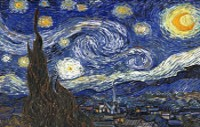

In [17]:
img=cv2.imread("img_11.jpg")
cv2_imshow(img)

**SEPARATE CHANNELS**

Blue Channel:


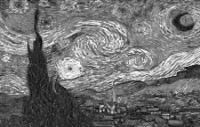

Red Channel:


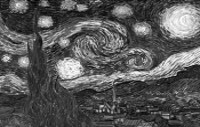

Green Channel:


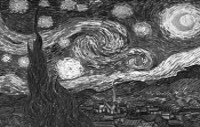

In [18]:
blue_channel=img[:,:,0]
green_channel=img[:,:,1]
red_channel=img[:,:,2]
print("Blue Channel:")
cv2_imshow(blue_channel)
print("Red Channel:")
cv2_imshow(red_channel)
print("Green Channel:")
cv2_imshow(green_channel)



**COMPUTE SVD PER CHANNEL**

In [19]:
blue_U, blue_S, blue_Vt = np.linalg.svd(blue_channel, full_matrices=True)
green_U, green_S, green_Vt = np.linalg.svd(green_channel, full_matrices=True)
red_U, red_S, red_Vt = np.linalg.svd(red_channel, full_matrices=True)
singular_values_chanels=np.array([blue_S,red_S,green_S])

**PLOT SINGULAR VALUES WITH LOG TRANSFORMATION**

Text(0, 0.5, 'Log Singular Value')

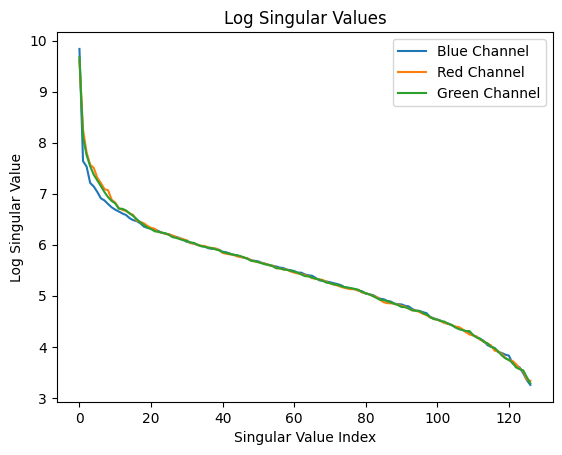

In [20]:
n_singular_values=min(img.shape[0],img.shape[1])
index=np.arange(0,n_singular_values)
for i in singular_values_chanels:
  plt.plot(index,np.log(i))
plt.title("Log Singular Values")
plt.legend(["Blue Channel","Red Channel","Green Channel"])
plt.xlabel("Singular Value Index")
plt.ylabel("Log Singular Value")


**CALCULATE PONDERATE CUMULATIVE SUM**

Text(0, 0.5, 'Cumulative Ponderate Singular Value')

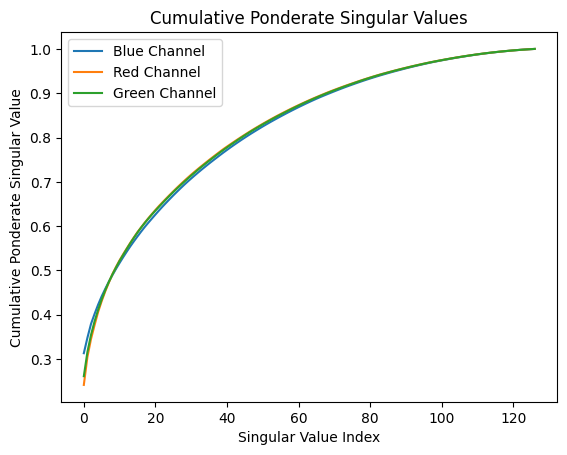

In [21]:
cum_ponderate_singular_values_list=[]
for i in singular_values_chanels:
  sum_singular_values=np.sum(i)
  ponderate_singular_values=i/sum_singular_values
  cum_ponderate_singular_values=np.cumsum(ponderate_singular_values)
  cum_ponderate_singular_values_list.append(cum_ponderate_singular_values)
  plt.plot(index,cum_ponderate_singular_values)
plt.title("Cumulative Ponderate Singular Values")
plt.legend(["Blue Channel","Red Channel","Green Channel"])
plt.xlabel("Singular Value Index")
plt.ylabel("Cumulative Ponderate Singular Value")

**GET SINGULAR VALUES THAT KEEP 95% OF THE INFORMATION**

In [22]:
retained_singular_values = []
for i in range(len(singular_values_chanels)):
  singular_values=singular_values_chanels[i]
  cum_ponderate_singular_values=cum_ponderate_singular_values_list[i]
  retained_channel_singular_values=singular_values[cum_ponderate_singular_values<=0.95]
  retained_singular_values.append(retained_channel_singular_values)

**PLOT RETAINED SINGULAR VALUES WITH LOG TRANSFORMATION**

Text(0, 0.5, 'Log Retained Singular Value')

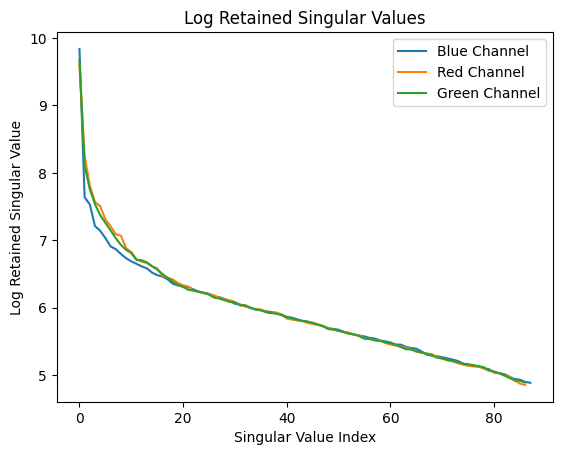

In [23]:
for i in retained_singular_values:
  index=np.arange(0,len(i))
  plt.plot(index,np.log(i))
plt.title("Log Retained Singular Values")
plt.legend(["Blue Channel","Red Channel","Green Channel"])
plt.xlabel("Singular Value Index")
plt.ylabel("Log Retained Singular Value")


**CHANNELS RESULT**

Blue Channel:


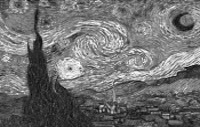

Red Channel:


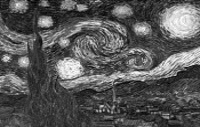

Green Channel:


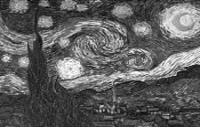

In [24]:
blue_U_retained=blue_U[:,:len(retained_singular_values[0])]
blue_Vt_retained=blue_Vt[:len(retained_singular_values[0]),:]
blue_channel_retained=blue_U_retained@np.diag(retained_singular_values[0])@blue_Vt_retained

red_U_retained=red_U[:,:len(retained_singular_values[1])]
red_Vt_retained=red_Vt[:len(retained_singular_values[1]),:]
red_channel_retained=red_U_retained@np.diag(retained_singular_values[1])@red_Vt_retained

green_U_retained=green_U[:,:len(retained_singular_values[2])]
green_Vt_retained=green_Vt[:len(retained_singular_values[2]),:]
green_channel_retained=green_U_retained@np.diag(retained_singular_values[2])@green_Vt_retained


print("Blue Channel:")
cv2_imshow(blue_channel_retained)
print("Red Channel:")
cv2_imshow(red_channel_retained)
print("Green Channel:")
cv2_imshow(green_channel_retained)



**RECONSTRUCT IMAGE**

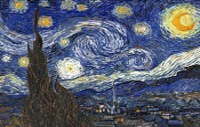

In [25]:
image_retained=np.zeros(img.shape)
image_retained[:,:,0]=blue_channel_retained
image_retained[:,:,1]=green_channel_retained
image_retained[:,:,2]=red_channel_retained
cv2_imshow(image_retained)

**AVERAGE SINGULAR VALUES OF CHANNELS**

Text(0, 0.5, 'Log Singular Value')

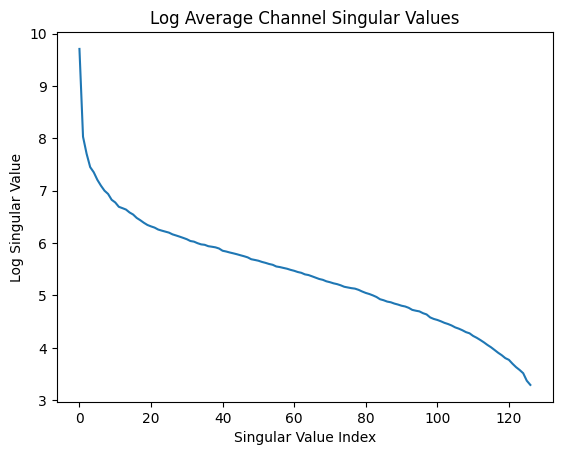

In [26]:
average_S=(blue_S+red_S+green_S)/3
index=np.arange(0,len(average_S))
plt.plot(index,np.log(average_S))
plt.title("Log Average Channel Singular Values")
plt.xlabel("Singular Value Index")
plt.ylabel("Log Singular Value")

**DISCARD FIRST K  PERCENTAGE OF SINGULAR VALUES**

Text(0, 0.5, 'Singular Value')

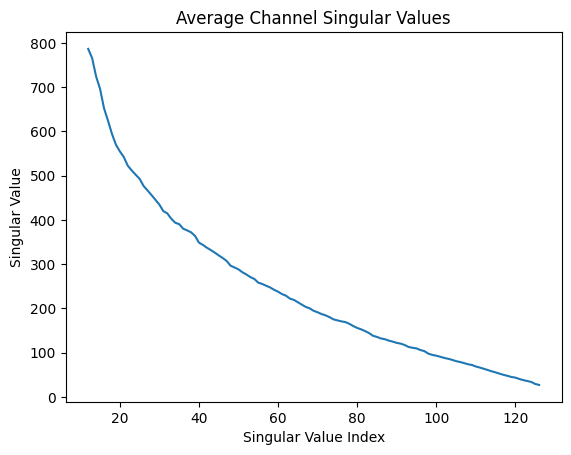

In [27]:
k=0.1
n=int(k*len(average_S))
k_average_S=average_S[n:]
k_index=index[n:]
plt.plot(k_index,k_average_S)
plt.title("Average Channel Singular Values")
plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value")


**DEFINE TYPE OF DECAY FUNCTIONS**

In [28]:
def linear(x,a,b):
  return a*x + b
def exponential(x,a,b,c):
  return a*np.exp((-b)*x) + c
def algebraic(x,a,b,c):
  return a*(x**(-b)) + c
decay_functions=[linear,exponential,algebraic]

**GET BEST FIT-CURVE PARAMETERS OF DECAY FUNCTIONS**

/tmp/ipykernel_760/2782460972.py:4: RuntimeWarning: overflow encountered in exp
  return a*np.exp((-b)*x) + c
/tmp/ipykernel_760/2782460972.py:6: RuntimeWarning: overflow encountered in power
  return a*(x**(-b)) + c
/tmp/ipykernel_760/2782460972.py:6: RuntimeWarning: overflow encountered in multiply
  return a*(x**(-b)) + c


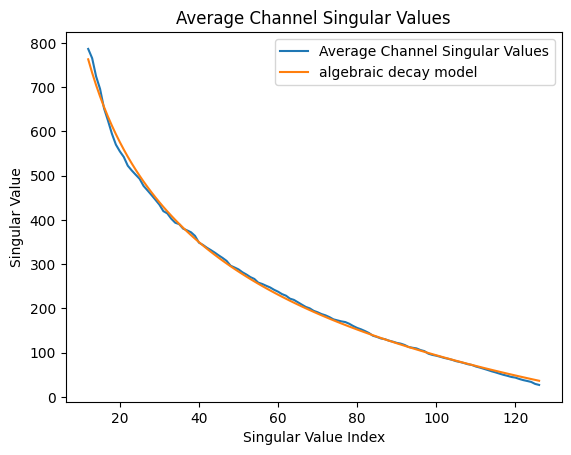

In [29]:
old_f_error=1e10
best_decay_function=None
for f in decay_functions:
  popt,pcov = curve_fit(f, k_index, k_average_S)
  prediction = f(k_index, *popt)
  error = np.mean((k_average_S - prediction)**2)
  if error<old_f_error:
    old_f_error=error
    best_decay_function=(f,popt)
decay_function,parameters=best_decay_function
model_k_average_S=decay_function(k_index,*parameters)
plt.plot(k_index,k_average_S,label="Average Channel Singular Values")
plt.plot(k_index,model_k_average_S,label=f"{decay_function.__name__} decay model")
plt.title("Average Channel Singular Values")
plt.xlabel("Singular Value Index")
plt.ylabel("Singular Value")
plt.legend()

#**PCA WITH  TRANSFORMED RANDOM POINTS**
---

**DEFINE AUXILIAR FUNCTIONS**

In [12]:
def random_points_generator(x_mean,y_mean,x_std,y_std,n_samples,x_seed,y_seed):
  x_distribution= norm(x_mean,x_std)
  y_distribution= norm(y_mean,y_std)
  x_samples=x_distribution.rvs(n_samples,random_state=x_seed)
  y_samples=y_distribution.rvs(n_samples, random_state=y_seed)
  points=np.column_stack((x_samples,y_samples))
  return points

def apply_transformation(points,transformation_matrix):
  transformed_points=points@transformation_matrix.T
  return transformed_points

**GET RANDOM POINTS**



Text(0, 0.5, 'Y-axis')

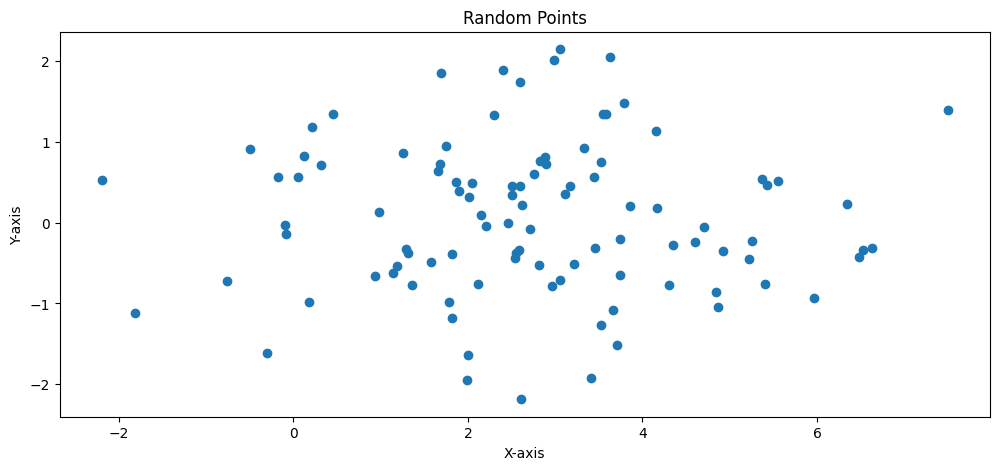

In [52]:
x_seed=45
y_seed=13
x_mean=3
y_mean=0
x_std=2
y_std=1
n_samples = 100
points=random_points_generator(x_mean,y_mean,x_std,y_std,n_samples,x_seed,y_seed)

#Plot graphs
fig,axis =plt.subplots(1,1,figsize=(12,5),sharex=True,sharey=True)

#Plot random points
axis.scatter(points[:,0],points[:,1])
axis.set_title("Random Points")
axis.set_xlabel("X-axis")
axis.set_ylabel("Y-axis")

Text(0, 0.5, 'Y-axis')

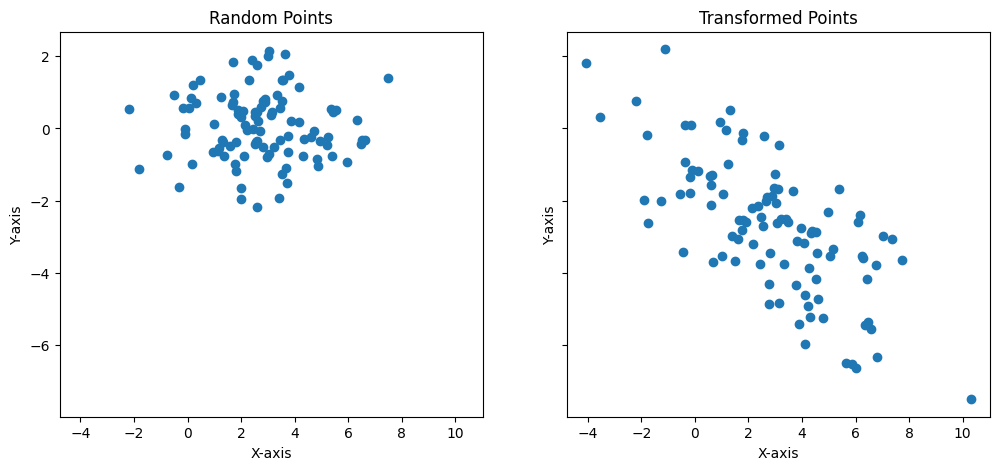

In [53]:
transformation_matrix=np.array([[1,2],[-1,0]])
transformed_points=apply_transformation(points,transformation_matrix)

#Plot graphs
fig,axis =plt.subplots(1,2,figsize=(12,5),sharex=True,sharey=True)

#Plot random points
axis[0].scatter(points[:,0],points[:,1])
axis[0].set_title("Random Points")
axis[0].set_xlabel("X-axis")
axis[0].set_ylabel("Y-axis")

#Plot transformed points
axis[1].scatter(transformed_points[:,0],transformed_points[:,1])
axis[1].set_title("Transformed Points")
axis[1].set_xlabel("X-axis")
axis[1].set_ylabel("Y-axis")


**APPLY PCA**

Text(0, 0.5, 'Y-axis')

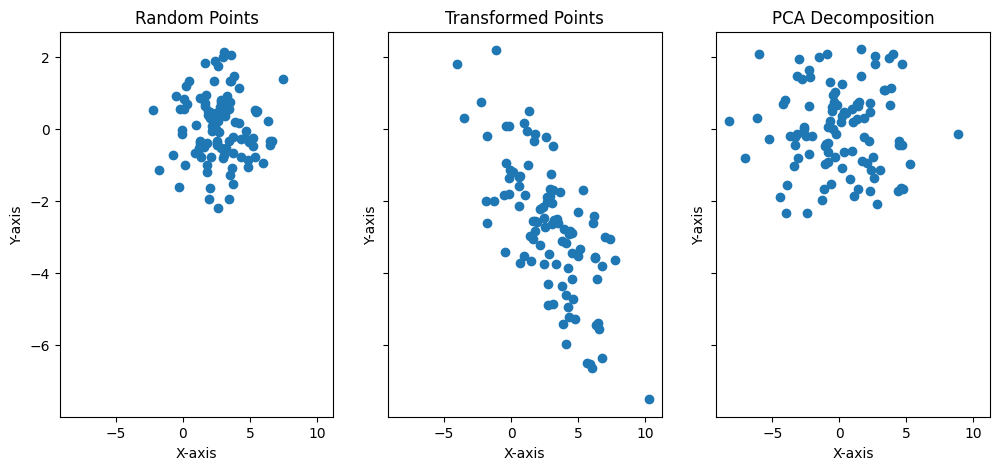

In [49]:
pca=PCA(n_components=2)
pca.fit(transformed_points)
decompose_points=pca.transform(transformed_points)

#Plot graphs
fig,axis =plt.subplots(1,3,figsize=(12,5),sharex=True,sharey=True)

#Plot random points
axis[0].scatter(points[:,0],points[:,1])
axis[0].set_title("Random Points")
axis[0].set_xlabel("X-axis")
axis[0].set_ylabel("Y-axis")

#Plot transformed points
axis[1].scatter(transformed_points[:,0],transformed_points[:,1])
axis[1].set_title("Transformed Points")
axis[1].set_xlabel("X-axis")
axis[1].set_ylabel("Y-axis")

#Plot decompose points
axis[2].scatter(decompose_points[:,0],decompose_points[:,1])
axis[2].set_title("PCA Decomposition")
axis[2].set_xlabel("X-axis")
axis[2].set_ylabel("Y-axis")

**STATISTICAL DATA**

In [54]:
data={}
for i in [points,transformed_points,decompose_points]:
  covariance_matrix=np.cov(i,rowvar=False)
  x_variance=covariance_matrix[0,0]
  y_variance=covariance_matrix[1,1]
  covariance=covariance_matrix[0,1]
  statistical_data=[x_variance,y_variance,covariance]
  if i is points:
    data["points"]=statistical_data
  elif i is transformed_points:
    data["transformed_points"]=statistical_data
  else:
    data["decompose_points"]=statistical_data


**PLOT STATISTICS**

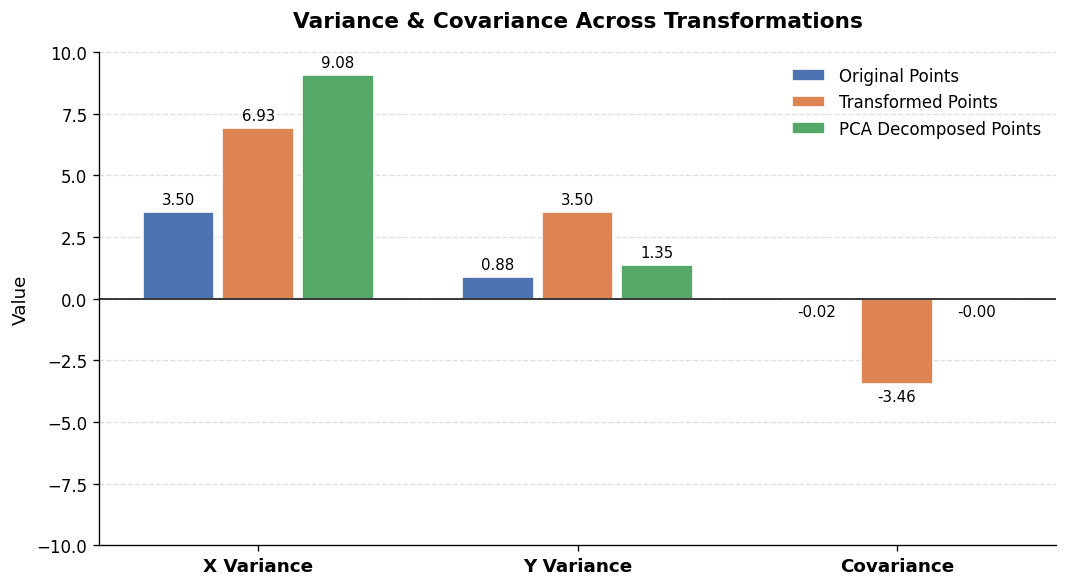

In [55]:

categories = ["X Variance", "Y Variance", "Covariance"]
x = np.arange(len(categories))
n_bars = len(data)
total_width = 0.75
bar_width = total_width / n_bars

# Clean modern color palette & human-readable legend labels
colors = ["#4C72B0", "#DD8452", "#55A868"]
display_names = {
    "points": "Original Points",
    "transformed_points": "Transformed Points",
    "decompose_points": "PCA Decomposed Points",
}

fig, ax = plt.subplots(figsize=(9, 5), dpi=120)

for i, (label, values) in enumerate(data.items()):
  offset = (i - (n_bars - 1) / 2) * bar_width
  rects = ax.bar(
      x + offset,
      values,
      bar_width * 0.9,  # 0.9 adds subtle breathing room between bars
      label=display_names.get(label, label),
      color=colors[i % len(colors)],
      edgecolor="white",
      linewidth=1,
      zorder=3,
  )
  # Display the exact value above/below every bar (even near-zero ones!)
  ax.bar_label(rects, fmt="%.2f", padding=3, fontsize=9, fontweight="medium")

# Add zero baseline and horizontal grid behind the bars
ax.axhline(0, color="black", linewidth=0.9, zorder=4)
ax.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)

# Give extra vertical padding so bar labels don't touch the top/bottom borders
ax.set_ylim(-10, 10)

# Clean up borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Labels and title
ax.set_xticks(x)
ax.set_xticklabels(categories, fontsize=11, fontweight="bold")
ax.set_ylabel("Value", fontsize=11)
ax.set_title(
    "Variance & Covariance Across Transformations",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
ax.legend(frameon=False, fontsize=10, loc="upper right")

plt.tight_layout()
plt.show()